# 04b - Regressão: taxa de juro no momento do pedido (T0)

Bloco 4 do plano da Parte 2. Compara todos os modelos da regressão na validação cruzada temporal (6 folds trimestrais em 2013–2014) e interpreta o melhor. O teste de 2015 **não** é usado aqui: fica para a avaliação final (bloco 8).

**Antes de correr:** a grelha completa, no terminal, a partir da pasta do projeto (pode demorar horas; retoma onde parou):

```
python scripts/run_cv.py regression
```

| Requisito do enunciado | Onde |
|---|---|
| kNN de raiz aplicado à regressão | kNN no catálogo (`knn.py`) |
| Dois modelos do scikit-learn que não são *ensembles* | Ridge e árvore de decisão |
| Um *ensemble* de *bagging* e um de *boosting* | Random Forest e LightGBM |
| Rede neuronal em TensorFlow | MLP (`deep.py`) |
| *"Same eligible evaluation cohort and split definitions for all models"* | Secção 1: todos os modelos usam o mesmo runner |
| *"Report training sample sizes, tuning procedures, and any computational limitations"* | Secções 1, 4 e 6 |
| *"One comparison table for each task, including baselines"* e MAE, RMSE e R² | Secção 3 |
| *"The mean and the variation of the metric in the cross-validation procedures"* | Secções 3 e 5 |
| *"Strengths, weaknesses and lessons learned"* | Secções 7 e 8 |

In [1]:
# Setup: imports e caminhos do projeto
import sys
import time
from pathlib import Path

# Importar o pacote do projeto.
try:
    import lending
except ModuleNotFoundError:
    for parent in [Path.cwd(), *Path.cwd().parents]:
        if (parent / "src" / "lending").is_dir():
            sys.path.insert(0, str(parent / "src"))
            break
    import lending

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lending import config
from lending.experiment import CrossValidationRunner
from lending.model_analysis import CVAnalysis
from lending.model_catalog import KNN_REGRESSION_SAMPLE, regression_specs
from lending.plot_style import CATEGORICAL, apply_style
from lending.storage import PickleStore

apply_style()
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RUN_MISSING = False   # True corre aqui os ajustes que faltarem (melhor usar o scripts/run_cv.py)

## 1. Dados, folds e tamanhos de treino

Todos os modelos usam a mesma coorte (empréstimos de 2013–2014), ordenada por `issue_d`, e os mesmos 6 folds: cada fold treina com todos os trimestres anteriores e valida no seguinte. O kNN usa uma amostra de 50 000 empréstimos do treino de cada fold (semente 42), porque a previsão custa pedidos × treino; os outros modelos usam o treino inteiro.

In [2]:
data = PickleStore.load(config.REG_DEV_PKL, expected_type=pd.DataFrame)
runner = CrossValidationRunner("regression", verbose=True)
specs = {spec.name: spec for spec in regression_specs()}

folds = runner.folds(data)
folds["linhas treino kNN"] = folds["linhas treino"].clip(upper=KNN_REGRESSION_SAMPLE)
print(f"{len(data):,} empréstimos | {len(runner.columns)} colunas de entrada | modelos: {list(specs)}")
folds

370,278 empréstimos | 90 colunas de entrada | modelos: ['Mediana', 'Mediana por prazo', 'kNN', 'Ridge', 'Árvore', 'Random Forest', 'LightGBM', 'MLP']


,treino,validação,linhas treino,linhas validação,linhas treino kNN
fold,,,,,
1,2013Q1 a 2013Q2,2013Q3,53350,37562,50000
2,2013Q1 a 2013Q3,2013Q4,90912,43855,50000
3,2013Q1 a 2013Q4,2014Q1,134767,47388,50000
4,2013Q1 a 2014Q1,2014Q2,182155,55332,50000
5,2013Q1 a 2014Q2,2014Q3,237487,58693,50000
6,2013Q1 a 2014Q3,2014Q4,296180,74098,50000


## 2. Estado da grelha

40 configurações (mais as 2 *baselines*) × 6 folds. O CSV `reports/results/regression_cv.csv` tem uma linha por ajuste.

In [3]:
planned = {(name, cid, f) for name, spec in specs.items() for cid, _ in spec.configs()
           for f in range(1, len(folds) + 1)}
done = {(r.model, r.config_id, r.fold) for r in runner.results().itertuples()}
missing = planned - done
print(f"{len(planned & done)} de {len(planned)} ajustes feitos")
if missing and RUN_MISSING:
    runner.run(data, list(specs.values()))
elif missing:
    pending = pd.Series([m for m, _, _ in missing]).value_counts()
    print("Faltam (corre 'python scripts/run_cv.py regression'):", pending.to_dict())

analysis = CVAnalysis(runner, data)

252 de 252 ajustes feitos


## 3. Tabela de comparação

Melhor configuração de cada modelo, escolhida pelo MAE médio nos 6 folds; os valores são média ± desvio-padrão entre folds. A melhoria é a redução do MAE face às *baselines*.

In [4]:
table = runner.comparison_table()
table["melhoria vs mediana por prazo (%)"] = analysis.improvement("Mediana por prazo")
table["melhoria vs mediana (%)"] = analysis.improvement("Mediana")
table

,params,n_train,mae,rmse,r2,fit_seconds,melhoria vs mediana por prazo (%),melhoria vs mediana (%)
model,,,,,,,,
LightGBM,"{""learning_rate"": 0.05, ""num_leaves"": 63}",165808,2.144 ± 0.419,2.697 ± 0.494,0.603 ± 0.157,7.8,31.8,38.9
MLP,"{""hidden_layers"": [256, 128, 64], ""learning_ra...",165808,2.165 ± 0.346,2.723 ± 0.414,0.600 ± 0.141,40.9,31.2,38.4
Ridge,"{""alpha"": 10.0}",165808,2.221 ± 0.332,2.776 ± 0.388,0.587 ± 0.133,0.3,29.4,36.7
Random Forest,"{""max_features"": 0.3, ""min_samples_leaf"": 10}",165808,2.257 ± 0.292,2.821 ± 0.329,0.576 ± 0.121,24.6,28.2,35.7
Árvore,"{""max_depth"": 12, ""min_samples_leaf"": 50}",165808,2.445 ± 0.290,3.078 ± 0.328,0.496 ± 0.131,9.2,22.3,30.4
kNN,"{""n_neighbors"": 31, ""weights"": ""distance""}",50000,2.490 ± 0.153,3.176 ± 0.162,0.471 ± 0.075,0.1,20.8,29.1
Mediana por prazo,{},165808,3.144 ± 0.196,3.929 ± 0.194,0.195 ± 0.056,0.0,-0.0,10.5
Mediana,{},165808,3.512 ± 0.162,4.404 ± 0.151,-0.011 ± 0.019,0.0,-11.7,-0.0


**Como ler:** a *baseline* exigente é a mediana por prazo (o prazo, sozinho, separa a taxa em mais de 4 p.p.). Um modelo só acrescenta valor se o MAE ficar claramente abaixo dela. Quando a diferença entre dois modelos é menor do que o desvio entre folds, não há um vencedor claro na validação cruzada; o bootstrap emparelhado no teste (bloco 8) diz se a diferença se mantém.

## 4. Afinação: efeito dos hiperparâmetros

Para cada modelo, todas as configurações da grelha com o MAE médio e o desvio nos folds. É o procedimento de afinação que o enunciado pede para reportar.

In [5]:
for name in [m for m in specs if specs[m].param_grid]:
    if name in analysis.models:
        print(f"\n{name}")
        display(analysis.params_table(name, metrics=["mae"])
                .round({"mae_mean": 3, "mae_std": 3, "fit_seconds": 1}))


kNN


,n_neighbors,weights,mae_mean,mae_std,fit_seconds,n_folds
0,31,distance,2.490,0.153,0.1,6
1,15,distance,2.490,0.165,0.1,6
2,15,uniform,2.494,0.163,0.1,6
3,31,uniform,2.495,0.152,0.1,6
4,51,distance,2.506,0.146,0.1,6
5,51,uniform,2.511,0.145,0.1,6
6,101,distance,2.541,0.136,0.1,6
7,101,uniform,2.546,0.135,0.1,6
8,5,distance,2.590,0.182,0.1,6
9,5,uniform,2.594,0.181,0.1,6



Ridge


,alpha,mae_mean,mae_std,fit_seconds,n_folds
0,10.000,2.221,0.332,0.3,6
1,1.000,2.221,0.332,0.3,6
2,0.100,2.221,0.332,0.3,6
3,0.010,2.221,0.332,0.3,6
4,0.001,2.221,0.332,0.3,6
5,100.000,2.221,0.331,0.3,6



Árvore


,max_depth,min_samples_leaf,mae_mean,mae_std,fit_seconds,n_folds
0,12,50,2.445,0.290,9.2,6
1,12,200,2.486,0.243,8.5,6
2,8,50,2.522,0.281,6.6,6
3,8,200,2.541,0.258,6.4,6
4,6,50,2.605,0.240,4.9,6
5,6,200,2.608,0.239,5.1,6
6,4,200,2.714,0.203,3.4,6
7,4,50,2.715,0.203,3.5,6


... (2 outputs left out)


LightGBM


,learning_rate,num_leaves,mae_mean,mae_std,fit_seconds,n_folds
0,0.05,63,2.144,0.419,7.8,6
1,0.10,63,2.146,0.416,6.0,6
2,0.10,31,2.148,0.418,4.8,6
3,0.05,31,2.155,0.421,6.1,6
4,0.10,15,2.159,0.423,4.0,6
5,0.05,15,2.172,0.419,4.5,6



MLP


,hidden_layers,learning_rate,mae_mean,mae_std,fit_seconds,n_folds
0,"[256, 128, 64]",0.0003,2.165,0.346,40.9,6
1,"[256, 128, 64]",0.0010,2.186,0.361,37.8,6
2,"[128, 64]",0.0010,2.195,0.372,27.0,6
3,[64],0.0003,2.207,0.376,27.7,6
4,"[128, 64]",0.0003,2.212,0.385,38.2,6
5,[64],0.0010,2.215,0.371,16.3,6


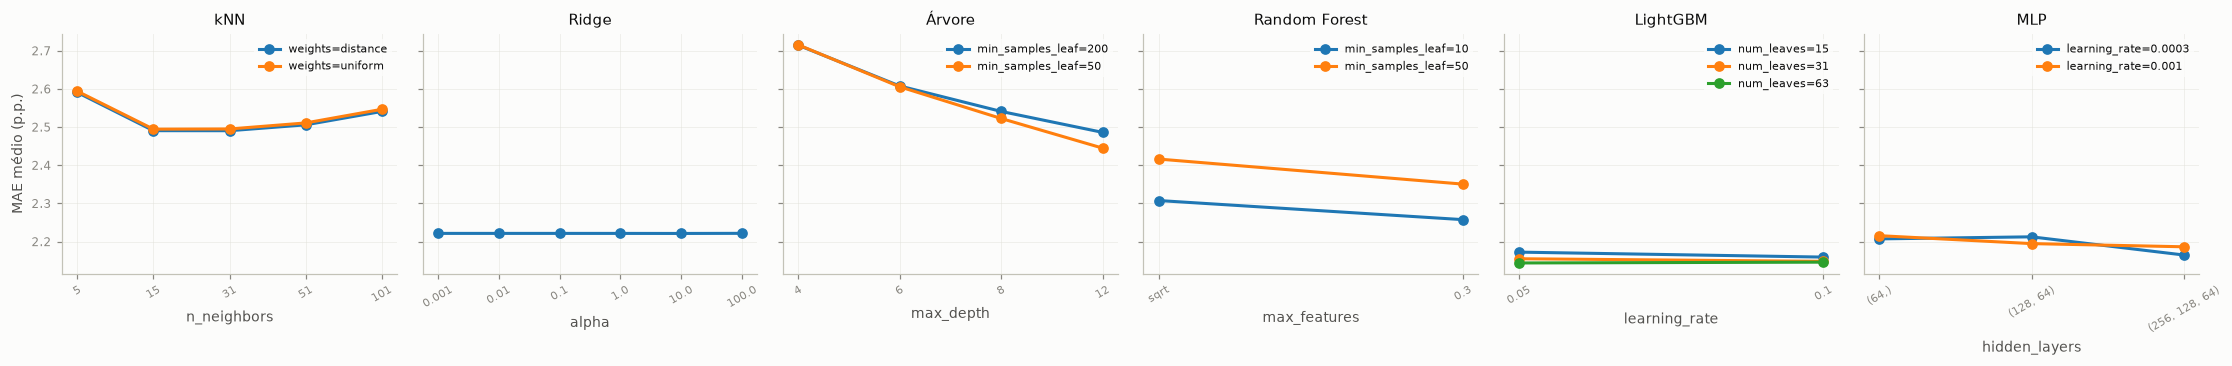

In [6]:
# Uma figura por família: o 1.º hiperparâmetro no eixo x, o 2.º como uma linha por valor
tuned = [m for m in specs if specs[m].param_grid and m in analysis.models]
fig, axes = plt.subplots(1, len(tuned), figsize=(3.4 * len(tuned), 3.4), sharey=True)
for ax, name in zip(np.atleast_1d(axes), tuned):
    analysis.plot_tuning(name, specs[name].param_grid, "mae", ax=ax)
    ax.tick_params(axis="x", rotation=30, labelsize=7)
np.atleast_1d(axes)[0].set_ylabel("MAE médio (p.p.)")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_reg_afinacao.png")
plt.show()

## 5. Variação ao longo dos folds

O MAE de cada trimestre de validação, na melhor configuração de cada modelo. Um erro que sobe nos trimestres mais recentes indica mudança temporal: o modelo é treinado com o passado e avaliado num período que já mudou.

,2013Q3,2013Q4,2014Q1,2014Q2,2014Q3,2014Q4
LightGBM,1.495,1.970,2.303,2.147,2.170,2.777
MLP,1.708,1.970,2.391,2.059,2.157,2.704
Ridge,1.727,2.109,2.254,2.204,2.271,2.762
Random Forest,1.901,2.117,2.249,2.200,2.297,2.780
Árvore,2.026,2.317,2.481,2.428,2.498,2.918
kNN,2.368,2.465,2.431,2.378,2.517,2.782
Mediana por prazo,3.375,3.202,2.903,2.913,3.176,3.297
Mediana,3.723,3.650,3.324,3.340,3.549,3.484


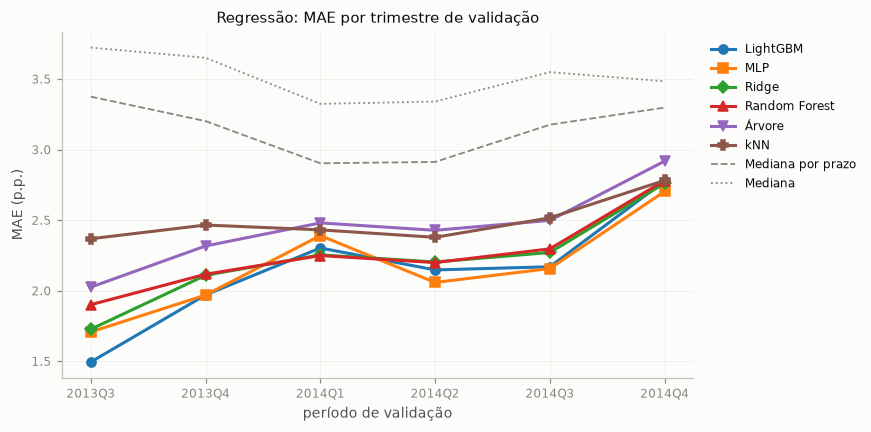

In [7]:
display(analysis.fold_table("mae").round(3))
fig, ax = plt.subplots(figsize=(8, 4))
analysis.plot_folds("mae", ax=ax)
ax.set(ylabel="MAE (p.p.)", title="Regressão: MAE por trimestre de validação")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_reg_mae_por_fold.png")
plt.show()

## 6. Custo computacional

Tempo de treino por modelo (todos os ajustes da grelha) e tempo médio por ajuste. O pré-processamento é ajustado uma vez por fold e partilhado por todos os modelos.

In [8]:
cost = analysis.cost_table()
print(f"Pré-processamento: {cost.attrs['pre_processamento_min']:.1f} min no total (6 folds)")
print(f"Treino de todos os modelos: {cost['treino_total_min'].sum():.0f} min")
cost

Pré-processamento: 0.0 min no total (6 folds)
Treino de todos os modelos: 33 min


,configuracoes,ajustes,treino_min_linhas,treino_max_linhas,treino_total_min,treino_medio_s,previsao_media_s
model,,,,,,,
MLP,6,36,53350,296180,18.78,31.31,0.27
Random Forest,4,24,53350,296180,6.09,15.21,0.39
Árvore,8,48,53350,296180,4.76,5.95,0.04
LightGBM,6,36,53350,296180,3.32,5.54,0.34
Ridge,6,36,53350,296180,0.18,0.29,0.03
kNN,10,60,50000,50000,0.10,0.10,44.02
Mediana por prazo,1,6,53350,296180,0.00,0.02,0.00
Mediana,1,6,53350,296180,0.00,0.01,0.00


## 7. Interpretação do melhor modelo

Tudo com as previsões fora do fold (validação), nunca com o teste.

### 7.1 Previsto contra real

Melhor modelo: LightGBM | {"learning_rate": 0.05, "num_leaves": 63}


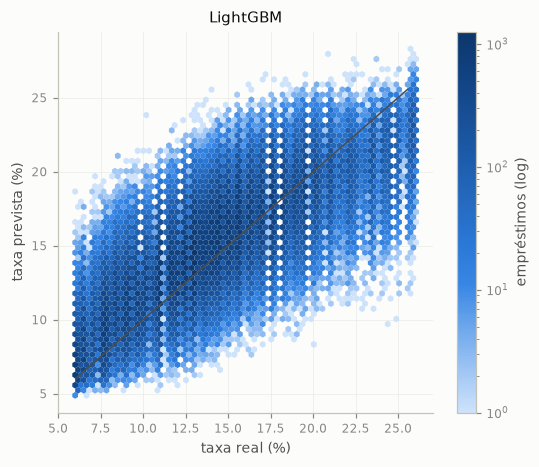

In [9]:
best_model = analysis.models[0]
print("Melhor modelo:", best_model, "|", runner.best().iloc[0]["params"])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
analysis.plot_pred_vs_real(best_model, ax=ax)
ax.set(xlabel="taxa real (%)", ylabel="taxa prevista (%)")
fig.savefig(config.FIGURES_DIR / "mod_reg_previsto_real.png")
plt.show()

**Como ler:** os pontos sobre a diagonal são previsões certas. Faixas horizontais indicam que o modelo dá a mesma taxa a empréstimos com taxas reais diferentes: a diferença está em informação que o modelo não tem (o sub-grau atribuído pela LendingClub, que é posterior ao pedido).

### 7.2 Viés ao longo do tempo

Resíduo médio (previsto − real) por mês de emissão: acima de 0, o modelo sobrestima a taxa. A regressão não pode usar a data (só existe depois do pedido), por isso mudanças na política de preços da LendingClub aparecem aqui.

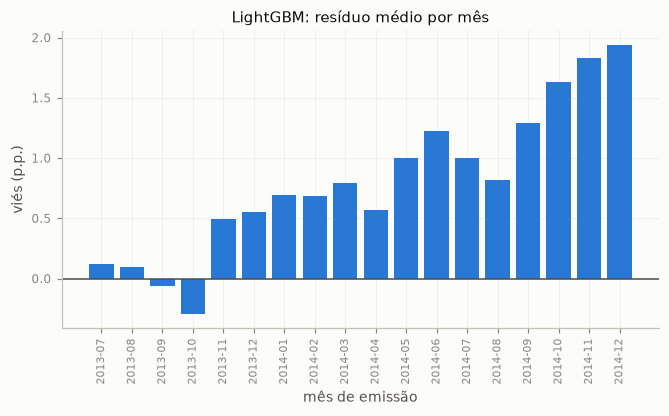

,2013-07,2013-08,2013-09,2013-10,2013-11,2013-12,2014-01,2014-02,2014-03,2014-04,2014-05,2014-06,2014-07,2014-08,2014-09,2014-10,2014-11,2014-12
n,11908.000,12670.000,12984.000,14124.000,14717.000,15014.000,15623.000,15258.000,16507.000,19066.000,19093.000,17173.000,29287.000,18802.000,10604.000,38755.000,25043.000,10300.000
vies,0.117,0.093,-0.064,-0.298,0.494,0.554,0.691,0.686,0.789,0.572,0.999,1.226,1.002,0.817,1.287,1.633,1.829,1.939
mae,1.481,1.510,1.495,1.196,2.313,2.363,2.271,2.295,2.340,2.022,2.176,2.255,2.040,2.159,2.547,2.720,2.807,2.922


In [10]:
by_month = analysis.residuals_by("issue_d", freq="M")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(by_month.index, by_month["vies"], color=CATEGORICAL[0])
ax.axhline(0, color="0.3", linewidth=1)
ax.set(xlabel="mês de emissão", ylabel="viés (p.p.)", title=f"{best_model}: resíduo médio por mês")
ax.tick_params(axis="x", rotation=90, labelsize=7)
fig.savefig(config.FIGURES_DIR / "mod_reg_vies_tempo.png")
plt.show()
by_month.T

### 7.3 Erro por prazo e por sub-grau

O sub-grau não é um preditor da regressão (é atribuído depois do pedido); usa-se aqui só para diagnóstico. Dentro de cada sub-grau, a LendingClub aplica praticamente a mesma taxa, por isso o viés por sub-grau mostra onde o perfil do pedido não chega para reconstruir o preço.

,n,vies,mae
36.0,221809,0.896,2.159
60.0,95119,0.916,2.363


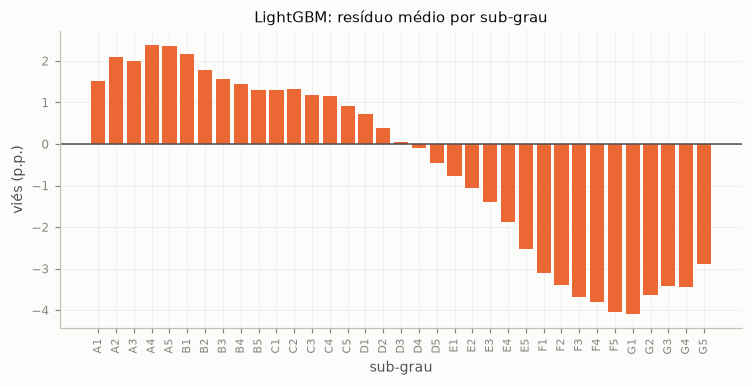

In [11]:
display(analysis.residuals_by("term"))
by_grade = analysis.residuals_by("sub_grade")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(by_grade.index.astype(str), by_grade["vies"], color=CATEGORICAL[1])
ax.axhline(0, color="0.3", linewidth=1)
ax.set(xlabel="sub-grau", ylabel="viés (p.p.)", title=f"{best_model}: resíduo médio por sub-grau")
ax.tick_params(axis="x", rotation=90, labelsize=7)
fig.savefig(config.FIGURES_DIR / "mod_reg_vies_subgrau.png")
plt.show()

**Como ler:** um viés positivo nos sub-graus bons (A) e negativo nos maus (F, G) quer dizer que o modelo "puxa" as taxas para o meio: subestima o risco dos piores pedidos e sobrestima o dos melhores.

### 7.4 Importância por permutação (último fold)

O melhor modelo é treinado no treino do último fold e cada coluna **original** é baralhada na validação desse fold (amostra de 20 000): a importância é o aumento do MAE. Baralhar uma coluna também baralha as *features* novas que dependem dela.

124 s


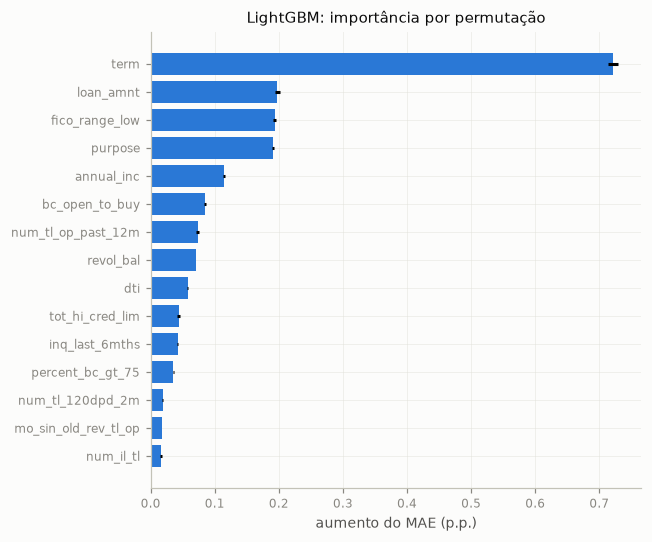

,importancia,desvio
term,0.7209,0.0081
loan_amnt,0.1976,0.0034
fico_range_low,0.1934,0.0025
purpose,0.1910,0.0013
annual_inc,0.1142,0.0016
bc_open_to_buy,0.0843,0.0019
num_tl_op_past_12m,0.0731,0.0019
revol_bal,0.0703,0.0003
dti,0.0576,0.0011
tot_hi_cred_lim,0.0435,0.0030


In [12]:
start = time.perf_counter()
importance = analysis.permutation_importance(specs[best_model], n_repeats=3, max_rows=20_000)
print(f"{time.perf_counter() - start:.0f} s")
fig, ax = plt.subplots(figsize=(6, 5))
analysis.plot_importance(importance, top=15, ax=ax, xlabel="aumento do MAE (p.p.)")
ax.set(title=f"{best_model}: importância por permutação")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_reg_importancia.png")
plt.show()
importance.head(15).round(4)

### 7.5 Coeficientes do Ridge

O Ridge é o modelo mais fácil de explicar: as colunas estão padronizadas, por isso cada coeficiente é a variação da taxa (p.p.) por um desvio-padrão da coluna, com as outras fixas. Treina-se a melhor configuração em todo o treino de 2013–2014.

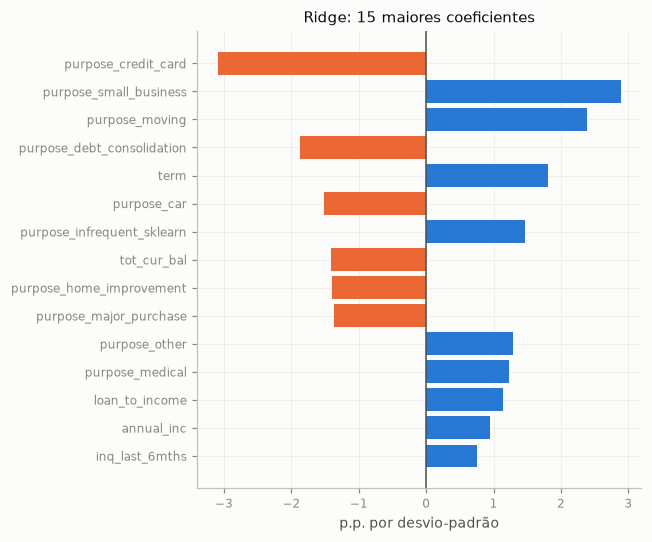

purpose_credit_card          -3.096
purpose_small_business        2.892
purpose_moving                2.378
purpose_debt_consolidation   -1.880
term                          1.813
purpose_car                  -1.516
purpose_infrequent_sklearn    1.461
tot_cur_bal                  -1.406
purpose_home_improvement     -1.393
purpose_major_purchase       -1.362
purpose_other                 1.292
purpose_medical               1.224
loan_to_income                1.143
annual_inc                    0.948
inq_last_6mths                0.752
dtype: float64

In [13]:
ridge = runner.refit(data, specs["Ridge"])["model"]
coef = pd.Series(ridge.coef_, index=ridge.feature_names_in_)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15)
fig, ax = plt.subplots(figsize=(6, 5))
ax.barh(top.index[::-1], top.to_numpy()[::-1],
        color=[CATEGORICAL[0] if v > 0 else CATEGORICAL[1] for v in top.to_numpy()[::-1]])
ax.axvline(0, color="0.3", linewidth=1)
ax.set(xlabel="p.p. por desvio-padrão", title="Ridge: 15 maiores coeficientes")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_reg_ridge_coef.png")
plt.show()
top.round(3)

## 8. Resumo

Os números para o relatório saem da célula seguinte. As frases do relatório devem dizer o que estes números significam, não repeti-los todos.

In [14]:
best = runner.best().set_index("model")
first, second = best.index[0], best.index[1]
gap = best.loc[second, "mae_mean"] - best.loc[first, "mae_mean"]
folds_mae = analysis.fold_table("mae").loc[first]
print(f"Melhor modelo: {first}, MAE {best.loc[first, 'mae_mean']:.3f} ± {best.loc[first, 'mae_std']:.3f} p.p. "
      f"(R² {best.loc[first, 'r2_mean']:.3f})")
print(f"Melhoria face à mediana por prazo: {analysis.improvement('Mediana por prazo')[first]:.1f}%")
print(f"2.º: {second}, a {gap:.3f} p.p.; "
      f"{'dentro' if gap < best.loc[first, 'mae_std'] else 'fora'} de um desvio-padrão entre folds")
print(f"MAE do melhor por fold: de {folds_mae.min():.3f} ({folds_mae.idxmin()}) a {folds_mae.max():.3f} ({folds_mae.idxmax()})")
print(f"Coluna mais importante (permutação): {importance.index[0]} (+{importance.iloc[0, 0]:.3f} p.p. de MAE)")
print(f"Tempo de treino da grelha: {analysis.cost_table()['treino_total_min'].sum():.0f} min")

Melhor modelo: LightGBM, MAE 2.144 ± 0.419 p.p. (R² 0.603)
Melhoria face à mediana por prazo: 31.8%
2.º: MLP, a 0.021 p.p.; dentro de um desvio-padrão entre folds
MAE do melhor por fold: de 1.495 (2013Q3) a 2.777 (2014Q4)
Coluna mais importante (permutação): term (+0.721 p.p. de MAE)
Tempo de treino da grelha: 33 min


**O que discutir no relatório** (secção de resultados da regressão):

1. Quanto o melhor modelo melhora a mediana por prazo, e se a diferença para o 2.º é maior do que a variação entre folds.
2. Que famílias funcionam melhor e porquê (relações não lineares e interações favorecem árvores e *ensembles*; o kNN sofre com ~100 dimensões).
3. A estabilidade ao longo dos folds (secção 5) e o viés ao longo do tempo (7.2): ligação à mudança temporal discutida na Parte 1.
4. O viés por sub-grau (7.3): o erro que sobra é o preço que só o sub-grau explica, que a regressão não pode usar.
5. As colunas mais importantes (7.4) e os coeficientes do Ridge (7.5), comparados com a EDA (FICO, prazo, utilização).
6. O custo computacional (secção 6) e as medidas tomadas (amostra do kNN, `max_samples` da Random Forest, paragem antecipada).